# 1 · Fermat e traiettoria rettilinea
Confrontiamo il minimo del tempo di volo con il percorso rettilineo che attraversa due mezzi:
$$t(\theta)=\frac{n_{LS}\,\ell_{LS}(\theta)+n_{acqua}\,\ell_{acqua}(\theta)}{c}.$$
Si usano **nLS = 1,54**, **nacqua = 1,33**, raggio LS **17,82 m**, come in `src/pmt.h`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

dati = Path("dati")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

import json
from scipy.optimize import minimize_scalar

esempio = json.loads((dati / "esempio.json").read_text())
z = np.loadtxt(dati / "z_mm.txt")
coseni = np.loadtxt(dati / "cos_theta.txt")
delta_mappa = np.loadtxt(dati / "delta_t_ns.txt")
assert delta_mappa.shape == (len(coseni), len(z))

### Un esempio di minimo
La sorgente è a z = 16,0 m; per il PMT 740 il minimo cade all’interno dell’intervallo angolare. Si confronta con il percorso rettilineo attraverso gli stessi due mezzi.

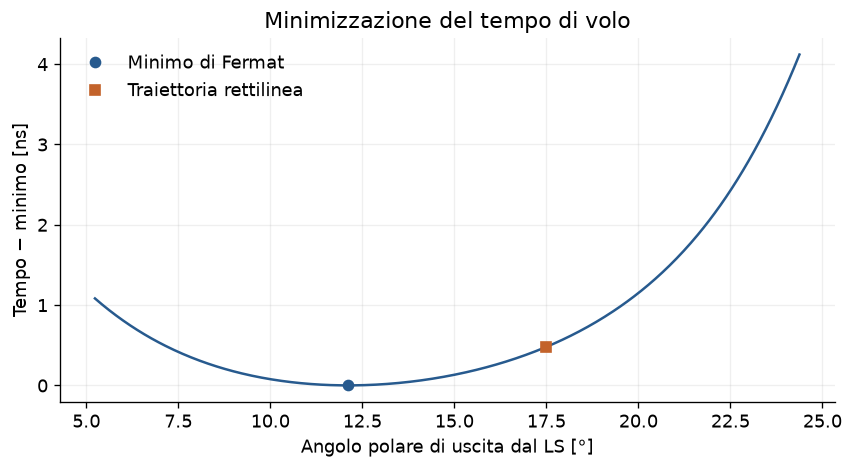

In [2]:
pmt = np.array(esempio["pmt_xyz_mm"])
R, zs = esempio["raggio_ls_mm"], esempio["z_sorgente_mm"]
r = np.linalg.norm(pmt)
theta_pmt = np.arccos(pmt[2] / r)
theta_lim = np.arccos(R / r)
limiti = (max(0, theta_pmt - theta_lim), min(np.pi, theta_pmt + theta_lim))

def tempo(theta):
    ls = np.sqrt(R**2 + zs**2 - 2 * R * zs * np.cos(theta))
    acqua = np.sqrt(r**2 + R**2 - 2 * r * R * np.cos(theta - theta_pmt))
    return (esempio["n_ls"] * ls + esempio["n_acqua"] * acqua) / 299.792458

scan = np.arange(*limiti, 0.001)
theta0 = scan[np.argmin(tempo(scan))]
fit = minimize_scalar(tempo, bounds=(max(limiti[0], theta0 - .001),
                                    min(limiti[1], theta0 + .001)), method="bounded",
                      options={"xatol": 1e-12})
assert limiti[0] < fit.x < limiti[1]
d = np.linalg.norm(pmt - [0, 0, zs])
b = zs * (pmt[2] - zs) / d
ls_lineare = -b + np.sqrt(b*b + R*R - zs*zs)
theta_lineare = np.arccos((zs + ls_lineare * (pmt[2] - zs) / d) / R)
np.testing.assert_allclose(tempo(theta_lineare), esempio["tof_lineare_ns"], atol=1e-8, rtol=0)
np.testing.assert_allclose(fit.fun, esempio["tof_fermat_ns"], atol=1e-5, rtol=0)

theta = np.linspace(min(fit.x, theta_lineare) - .12,
                    max(fit.x, theta_lineare) + .12, 500)
theta = theta[(theta >= limiti[0]) & (theta <= limiti[1])]
fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
ax.plot(np.degrees(theta), tempo(theta) - fit.fun, color="#275a8e")
ax.plot(np.degrees(fit.x), 0, "o", color="#275a8e", label="Minimo di Fermat")
ax.plot(np.degrees(theta_lineare), tempo(theta_lineare) - fit.fun, "s",
        color="#c3632b", label="Traiettoria rettilinea")
ax.set(xlabel="Angolo polare di uscita dal LS [°]", ylabel="Tempo − minimo [ns]",
       title="Minimizzazione del tempo di volo")
ax.legend(frameon=False)
ax.grid(alpha=.2)
plt.show()

### Risultato della scansione
Media sui PMT di $\Delta t=t_{Fermat}-t_{lineare}$, in 50 anelli angolari e 89 posizioni. La mappa conserva la scansione originale, compresi i minimi al bordo dell’intervallo, che non garantiscono un punto stazionario.

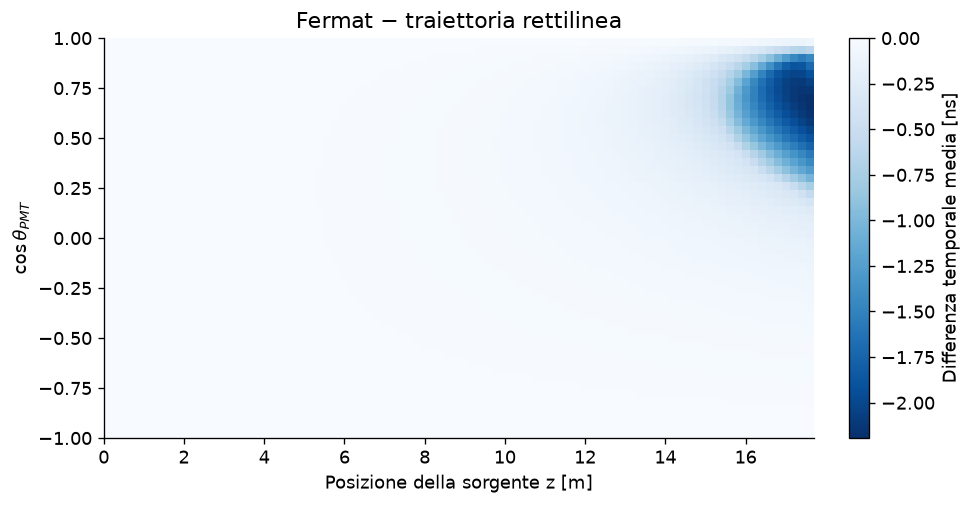

In [3]:
def bordi(centri):
    return np.r_[centri[0] - (centri[1] - centri[0]) / 2,
                 (centri[:-1] + centri[1:]) / 2,
                 centri[-1] + (centri[-1] - centri[-2]) / 2]

z_bordi = bordi(z) / 1000
z_bordi[0] = 0
fig, ax = plt.subplots(figsize=(8, 4.1), layout="constrained")
im = ax.pcolormesh(z_bordi, np.linspace(-1, 1, 51), delta_mappa,
                   cmap="Blues_r", vmin=delta_mappa.min(), vmax=0)
ax.set(xlabel="Posizione della sorgente z [m]", ylabel=r"$\cos\theta_{PMT}$",
       title="Fermat − traiettoria rettilinea", xlim=(0, z_bordi[-1]))
fig.colorbar(im, ax=ax, label="Differenza temporale media [ns]")
plt.show()

La differenza cresce vicino al bordo del rivelatore. Nell’esempio il percorso di Fermat riduce il tempo di circa **0,48 ns**.